<a href="https://colab.research.google.com/github/SebaSRomanH/CAPSTONE-UAI-CV-VIOLENCE/blob/main/Capstone_Vigia__X3D_EC2_T4_Colab_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VigIA · Benchmarking TSN (baseline) vs. X3D-Medium para detección de violencia
**Colab (interfaz) → túnel SSH → EC2 `g4dn.xlarge` (Tesla T4 16 GB) → Amazon S3**

Implementa el documento *Metodología de desarrollo para clasificación de video* (v2): clasificación binaria violencia / no violencia sobre tensores $B\times C\times T\times H\times W$, con el **baseline TSN** (ResNet-50, ya entrenado y guardado en S3: `modelamiento_version4/checkpoints/best_model.pt`) y la **Rama A, X3D-Medium** (Feichtenhofer, 2020), afinado en dos fases.

| Sección | Contenido | Metodología |
|---|---|---|
| 0 | Conexión de Colab a la EC2 por SSH (paso a paso) | — |
| 1–2 | Imports y configuración (única celda editable) | — |
| 3 | Acceso a S3 y reproducibilidad | — |
| 4 | Manifest, mapeo binario de etiquetas y particiones sin fuga | 1.1 |
| 5 | Muestreo temporal por segmentos y preprocesamiento espacial | 1.2, 1.3 |
| 6 | Métricas y pruebas estadísticas | 5.1 |
| 7 | Baseline TSN: carga desde S3 y evaluación | 2 |
| 8 | Arquitectura X3D-Medium | 3.1 |
| 9 | Entrenamiento en dos fases con registro por época | 3.2 |
| 10 | Gráficos de todos los indicadores por época | 5.1, 5.2 |
| 11 | Evaluación final en test y comparación TSN vs. X3D | 5.1 |
| 12 | Viabilidad de ingeniería: FLOPs, VRAM, tiempos | 5.2 |
| 13 | Explicabilidad: Grad-CAM espaciotemporal | — |
| 14 | Galería de ejemplos bien y mal clasificados | — |
| 15 | Evaluación municipal (opcional), respaldo y referencias | — |

La Rama B (VideoMAE) no está implementada en este notebook.

## 0. Conexión de Colab a la EC2 por SSH

Colab es solo la pantalla: el código se ejecuta en la EC2 con la Tesla T4. La llave está en:

`C:\Users\Usuario\Desktop\Capstone\Código\Modelamiento_seba.pem`

### Parte A. Solo la primera vez

**A1. Permisos de la llave.** Abrir **PowerShell** (menú Inicio, escribir "PowerShell", Enter) y pegar:
```powershell
icacls "C:\Users\Usuario\Desktop\Capstone\Código\Modelamiento_seba.pem" /inheritance:r
icacls "C:\Users\Usuario\Desktop\Capstone\Código\Modelamiento_seba.pem" /grant:r "$($env:USERNAME):(R)"
```
Debe responder "Se procesaron correctamente 1 archivos".

**A2. Autorizar tu computador en AWS.**
1. Consola de AWS → **EC2** → **Instancias** → clic en tu instancia.
2. Pestaña **Seguridad** → clic en el grupo de seguridad (`sg-...`).
3. **Editar reglas de entrada** → agregar **Tipo: SSH**, **Origen: Mi IP** → **Guardar reglas**.

Si cambias de red (otra casa, la universidad), repetir A2.

**A3. Instalar Jupyter en la EC2.**
1. Encender la instancia (**Estado de la instancia** → **Iniciar instancia**) y copiar la **Dirección IPv4 pública**.
2. En PowerShell:
   ```powershell
   ssh -i "C:\Users\Usuario\Desktop\Capstone\Código\Modelamiento_seba.pem" ubuntu@IP_PUBLICA
   ```
   Si pregunta `yes/no`, escribir `yes`.
3. Ya dentro del servidor:
   ```bash
   /opt/pytorch/bin/python -m pip install -U notebook boto3 fvcore iopath
   /opt/pytorch/bin/python -m pip install --no-deps pytorchvideo==0.1.5
   sudo apt-get install -y tmux
   exit
   ```

### Parte B. Cada vez que trabajes

**B1. Encender la instancia** y copiar la IP pública (cambia en cada encendido).

**B2. Abrir la conexión con túnel** (en PowerShell; no cerrar esta ventana):
```powershell
ssh -i "C:\Users\Usuario\Desktop\Capstone\Código\Modelamiento_seba.pem" -L 8888:localhost:8888 ubuntu@3.19.29.34
```

**B3. Iniciar Jupyter** (en esa misma ventana):
```bash
tmux new -A -s jupyter
/opt/pytorch/bin/python -m jupyter notebook --ServerApp.allow_origin='https://colab.research.google.com' --port=8888 --ServerApp.port_retries=0 --no-browser
```
Copiar la dirección `http://localhost:8888/tree?token=...`. Si Jupyter ya estaba corriendo, `tmux new -A` entra a la sesión existente; si no se ve la dirección, salir con `Ctrl+B` y luego `D`, y ejecutar `/opt/pytorch/bin/python -m jupyter notebook list`.

**B4. Conectar Colab.** Flecha junto a **Conectar** → **Conectar a un entorno de ejecución local** → pegar la dirección → **Conectar**.

**B5. Verificar.** La celda de la sección 1 debe imprimir `Tesla T4`.

### Parte C. Al terminar

1. En PowerShell: `tmux attach -t jupyter`, luego `Ctrl+C`, luego `exit` dos veces.
2. En EC2: **Estado de la instancia** → **Detener instancia**. Nunca **Terminar**: borra el disco.

### Problemas frecuentes

| Mensaje | Solución |
|---|---|
| `Permission denied (publickey)` | Cambiar `ubuntu` por `ec2-user` |
| `Connection timed out` | Instancia apagada o IP no autorizada: repetir A2 |
| `UNPROTECTED PRIVATE KEY FILE` | Repetir A1 |
| `duplicate session: jupyter` | Usar `tmux new -A -s jupyter` |
| `No space left on device` | En la EC2: `df -h /` y borrar cachés antiguas (`~/capstone_x3d/cache_videos`) |

La llave está en la carpeta del proyecto: el `.gitignore` del repositorio debe incluir `*.pem`.

In [ ]:
import os, io, json, math, time, random, hashlib, shutil, threading, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import boto3
from botocore.exceptions import BotoCoreError, ClientError, NoCredentialsError
import cv2
import matplotlib.pyplot as plt
from matplotlib import animation
from tqdm.auto import tqdm
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix, roc_curve)
from IPython.display import display, Image

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet50

cv2.setNumThreads(1)
warnings.filterwarnings('ignore', category=FutureWarning)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'
print('PyTorch', torch.__version__, '| dispositivo:', torch.cuda.get_device_name(0) if AMP else 'CPU (solo para depurar)')

/opt/pytorch/lib/python3.13/site-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


PyTorch 2.14.1+cu130 | dispositivo: Tesla T4


## 2. Configuración
**Única celda editable.** Los valores por defecto reproducen la metodología: $N=16$ frames por segmentos homogéneos, *resize* del lado corto a 256 y recorte central 224, normalización ImageNet, sin aumentación estocástica, Fase 1 (5 épocas, $\eta=10^{-3}$) y Fase 2 (15 épocas, coseno desde $\eta=10^{-5}$), y umbral $\tau=0.5$.

`TSN_S3_KEY` apunta al mejor checkpoint del baseline (`modelamiento_version4/checkpoints/best_model.pt`). `TSN_TRAIN_KEYS_S3` (opcional) es un CSV con la columna `s3_key` de los videos usados para entrenar el TSN; si el checkpoint trae esa lista guardada, se detecta sola. Con esa lista, el notebook excluye del test los videos que el baseline ya vio. Sin ella, el TSN se rotula **"vio el test"** en todas las tablas y gráficos (ver sección 7).

En `MODO='PRUEBA'` se usan pocos videos y una época por fase: sirve para validar el pipeline, no para reportar resultados.

In [ ]:
# --- Experimento ---
MODO = 'COMPLETO'                       # 'PRUEBA' | 'COMPLETO'
SEED = 42
REANUDAR = True                       #controlar la continuidad de entrenamiento

# --- Datos ---
AWS_REGION = 'us-east-2'
S3_BUCKET = 'capstone-uai-cv'
MANIFEST_S3_KEY = 'df_manifest.csv'
MANIFEST_LOCAL = ''                   # ruta CSV local alternativa; '' = leer desde S3
CARPETA_MUNICIPAL = 'VideosTest Pozo Almonte'
COL_GRUPO = None                      # None = autodetectar video_original_id / scene_id / camera_id
VAL_FRAC, TEST_FRAC = 0.15, 0.15
N_PUBLICOS_PRUEBA, N_MUNICIPALES_PRUEBA = 400, 100
EVALUAR_MUNICIPAL = True

# --- Muestreo y preprocesamiento (metodología 1.2 y 1.3) ---
N_FRAMES = 16                         # 16 o 32
SHORT_SIDE, CROP = 256, 224
NORMALIZACION = 'imagenet'            # 'imagenet' (metodología) | 'kinetics' (estadísticas del preentrenamiento X3D)

# --- Baseline TSN (metodología 2) ---
TSN_S3_KEY = 'modelamiento_version4/checkpoints/best_model.pt'
TSN_TRAIN_KEYS_S3 = ''                # opcional: CSV con s3_key del entrenamiento del TSN (control de fuga)

# --- X3D-Medium (metodología 3) ---
FASE1_EPOCHS, FASE1_LR = (5, 1e-3) if MODO == 'PRUEBA' else (5, 1e-3)
FASE2_EPOCHS, FASE2_LR = (15, 1e-5) if MODO == 'PRUEBA' else (15, 1e-5)
UNFREEZE_STAGES = 2                   # Fase 2: bloques superiores descongelados (res4, res5) + cabeza
FREEZE_BN = True                      # estadísticas de BatchNorm congeladas (batch pequeño)
WEIGHT_DECAY = 1e-4
DROPOUT = 0.5
BATCH_SIZE, ACCUM_STEPS = 4, 2        # batch efectivo 8
THRESHOLD = 0.5                       # umbral operativo (metodología 5.1)

# --- Recursos ---
NUM_WORKERS = 4
CACHE_MAX_GB = 200
MAX_FRAMES_SECUENCIAL = 900

# --- Evaluación y visualización ---
N_BOOTSTRAP = 1000
N_EJEMPLOS_POR_TIPO = 2               # ejemplos por TP / TN / FP / FN en la galería
FRAMES_ANIMACION = 32                 # frames del video original en cada GIF

# --- Rutas y respaldo ---
BASE_DIR = Path.home() / 'capstone_vigia'
CACHE_DIR = BASE_DIR / 'cache_videos'
SPLITS_DIR = BASE_DIR / 'splits'
MODELS_DIR = BASE_DIR / 'modelos'
RUN_DIR = BASE_DIR / 'runs_v2' / MODO.lower() / f'x3d_m_n{N_FRAMES}_s{SEED}'
GUARDAR_S3 = False
S3_RESULT_PREFIX = 'resultados/vigia_v2/'

# --- Derivados (no editar) ---
MEAN, STD = {'imagenet': ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
             'kinetics': ([0.45] * 3, [0.225] * 3)}[NORMALIZACION]
EPOCHS = FASE1_EPOCHS + FASE2_EPOCHS
for d in (CACHE_DIR, SPLITS_DIR, MODELS_DIR, RUN_DIR):
    d.mkdir(parents=True, exist_ok=True)
cache_actual = sum(p.stat().st_size for p in CACHE_DIR.iterdir() if p.is_file())
disco_libre_gb = (shutil.disk_usage(CACHE_DIR).free + cache_actual) / 1024**3
CACHE_MAX_GB = min(CACHE_MAX_GB, max(1.0, disco_libre_gb - 15))

PALETA = ['#FF6F61', '#22D3EE', '#FBBF24', '#A78BFA', '#2DD4BF']
plt.style.use('dark_background')
plt.rcParams.update({'axes.prop_cycle': plt.cycler(color=PALETA), 'figure.dpi': 110, 'axes.grid': True,
                     'grid.alpha': 0.15, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Corrida: {RUN_DIR}\nCaché: hasta {CACHE_MAX_GB:.1f} GB (disco disponible {disco_libre_gb:.1f} GB)')

Corrida: /home/ubuntu/capstone_vigia/runs_v2/completo/x3d_m_n16_s42
Caché: hasta 159.3 GB (disco disponible 174.3 GB)


## 3. Acceso a S3 y reproducibilidad
La EC2 necesita un rol IAM con `s3:GetObject` y `s3:ListBucket` sobre el bucket. No pegar claves AWS en el notebook. Cada proceso del `DataLoader` crea su propio cliente `boto3`, y cada *worker* recibe una semilla derivada de `SEED`.

Si `TSN_S3_KEY` está vacío, la celda lista los checkpoints (`.pt`, `.pth`, `.ckpt`) del bucket para identificar el del baseline.

In [ ]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True


def seed_worker(_):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)


_S3_CLIENTS = {}
def s3():
    pid = os.getpid()
    if pid not in _S3_CLIENTS:
        _S3_CLIENTS[pid] = boto3.Session(region_name=AWS_REGION).client('s3')
    return _S3_CLIENTS[pid]


set_seed(SEED)
try:
    print('Identidad IAM:', boto3.Session(region_name=AWS_REGION).client('sts').get_caller_identity()['Arn'])
    if not MANIFEST_LOCAL:
        s3().head_object(Bucket=S3_BUCKET, Key=MANIFEST_S3_KEY)
    print('Acceso S3 verificado.')
except (ClientError, NoCredentialsError, BotoCoreError) as exc:
    raise RuntimeError('Sin acceso S3: revisa rol IAM, región y nombre del manifest.') from exc

if not TSN_S3_KEY:
    found = [(o['Key'], o['Size'] / 1024**2) for page in s3().get_paginator('list_objects_v2').paginate(Bucket=S3_BUCKET)
             for o in page.get('Contents', []) if o['Key'].lower().endswith(('.pt', '.pth', '.ckpt'))]
    print('TSN_S3_KEY vacío. Checkpoints en el bucket:' if found else 'No hay checkpoints .pt/.pth/.ckpt en el bucket.')
    for k, mb in found: print(f'  {k}  ({mb:.1f} MB)')

Identidad IAM: arn:aws:sts::362114671283:assumed-role/capstone-ec2-s3/i-0b97e6331b0c19357
Acceso S3 verificado.


## 4. Manifest, mapeo binario y particiones
**Mapeo binario (metodología 1.1).** Las fuentes usan esquemas de anotación distintos; el manifest ya trae `violento_label`. La tabla de auditoría cruza la **categoría original** (carpeta de origen en `s3_key`) con la etiqueta binaria, para verificar que cada categoría quedó en la clase correcta: conductas como robo sin agresión (`Burglary`, `Stealing`) **no** son violencia física y no deben quedar en $Y=1$.

**Particiones.** El conjunto que elige la mejor época (validación) es distinto del que reporta el desempeño (test). Se usa `StratifiedGroupKFold` estratificando por clase y fuente, y agrupando por video de origen cuando existe esa columna (clips de un mismo video nunca quedan en particiones distintas). Las particiones se guardan y se reutilizan, de modo que TSN y X3D se evalúan sobre exactamente el mismo test. El conjunto municipal (Pozo Almonte) queda fuera de entrenamiento y selección.

In [ ]:
def load_manifest():
    if MANIFEST_LOCAL:
        return pd.read_csv(MANIFEST_LOCAL)
    return pd.read_csv(io.BytesIO(s3().get_object(Bucket=S3_BUCKET, Key=MANIFEST_S3_KEY)['Body'].read()))


def to_label(series):
    mapping = {'violento': 1, 'no-violento': 0, 'violent': 1, 'non-violent': 0, '1': 1, '0': 0, '1.0': 1, '0.0': 0}
    return series.astype(str).str.strip().str.lower().map(mapping)


def stratified_group_split(df, frac, seed):
    n_splits = max(2, min(round(1 / frac), int(df['y'].value_counts().min())))
    strata = df['y'].astype(str) + '|' + df['fuente']
    if strata.value_counts().min() < n_splits:
        strata = df['y'].astype(str)
    rest, hold = next(StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed).split(df, strata, df['grupo']))
    return df.iloc[rest].copy(), df.iloc[hold].copy()


def build_splits(manifest):
    df = manifest.copy()
    df['s3_key'] = df['s3_key'].astype(str).str.strip()
    df = df[df['s3_key'].str.len() > 0].drop_duplicates('s3_key')
    df['y'] = to_label(df['violento_label'])
    col = lambda c: df[c].fillna('').astype(str) if c in df else pd.Series('', index=df.index)
    municipal = (col('Carpeta').str.contains('pozo almonte', case=False, regex=False)
                 | col('sub_dataset_label').str.strip().str.lower().eq('municipal')
                 | df['s3_key'].str.startswith(CARPETA_MUNICIPAL + '/'))
    excluded = col('exclude_from_training').str.strip().str.lower().isin({'true', '1', 'yes', 'si', 'sí'})
    df['fuente'] = df['s3_key'].str.split('/').str[1].fillna('desconocida')
    df['categoria'] = df['s3_key'].str.split('/').str[-2]
    gcol = COL_GRUPO or next((c for c in ['video_original_id', 'source_video_id', 'scene_id', 'camera_id', 'group_id'] if c in df), None)
    df['grupo'] = col(gcol) if gcol else df['s3_key']
    df.loc[df['grupo'] == '', 'grupo'] = df['s3_key']
    print('Columna de grupo:', gcol or 'ninguna (cada video es su propio grupo)')

    public = df[~municipal & ~excluded & df['y'].notna()].copy()
    holdout = df[municipal & df['y'].notna()].copy()
    public['y'] = public['y'].astype(int); holdout['y'] = holdout['y'].astype(int)
    if MODO == 'PRUEBA':
        # Garantizar exactamente N_PUBLICOS_PRUEBA repartidos equitativamente por clase
        n_por_clase = N_PUBLICOS_PRUEBA // 2
        public = pd.concat([g.sample(n=min(n_por_clase, len(g)), random_state=SEED) for _, g in public.groupby('y')])
        holdout = holdout.sample(n=min(N_MUNICIPALES_PRUEBA, len(holdout)), random_state=SEED)
    rest, test = stratified_group_split(public, TEST_FRAC, SEED)
    train, val = stratified_group_split(rest, VAL_FRAC / (1 - TEST_FRAC), SEED + 1)
    out = pd.concat([train.assign(split='train'), val.assign(split='val'), test.assign(split='test'),
                     holdout.assign(split='municipal')], ignore_index=True)
    return out[['s3_key', 'y', 'fuente', 'categoria', 'grupo', 'split']]


split_file = SPLITS_DIR / f'splits_v2_{MODO.lower()}_s{SEED}.csv'
if split_file.exists():
    # Eliminamos el split anterior para forzar la recreación con el tamaño correcto si es necesario
    split_file.unlink()

splits = build_splits(load_manifest())
splits.to_csv(split_file, index=False)
print('Particiones creadas:', split_file.name)

df_train, df_val, df_test, df_municipal = (splits[splits.split == s].reset_index(drop=True) for s in ('train', 'val', 'test', 'municipal'))
pub = splits[splits.split != 'municipal']
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    assert not set(pub[pub.split == a].grupo) & set(pub[pub.split == b].grupo), f'Grupo compartido {a}/{b}'

print('\nAuditoría del mapeo binario (categoría original x etiqueta):')
audit = pd.crosstab([pub.fuente, pub.categoria], pub.y).rename(columns={0: 'Y=0 no violento', 1: 'Y=1 violento'})
display(audit)
print('Tamaño de las particiones:')
display(splits.groupby(['split', 'y']).size().unstack(fill_value=0).rename(columns={0: 'no violento', 1: 'violento'}))

Columna de grupo: ninguna (cada video es su propio grupo)
Particiones creadas: splits_v2_completo_s42.csv

Auditoría del mapeo binario (categoría original x etiqueta):


y                         Y=0 no violento  Y=1 violento
fuente      categoria                                  
RWF         Figth                       0          1000
            NonFight                 1000             0
SCFD        fight                       0           150
            noFight                   150             0
UFC-Crime   Abuse                       0            50
            Assault                     0            50
            Burglary                    0           100
            Fighting                    0            50
            Normal Video              905             0
            Robbery                     0           150
            Shooting                    0            50
            Stealing                    0           100
            Vandalism                   0            50
XD-Violence Abuse                       0            38
            Fighting                    0           484
            Normal                   2349             0
            Riot                        0           473
            Shooting                    0           294

Tamaño de las particiones:


y,no violento,violento
split,,
test,630,434
train,3145,2171
val,629,434


## 5. Muestreo temporal y preprocesamiento espacial
**Muestreo por segmentación homogénea (metodología 1.2; Wang et al., 2016).** Un video de $F$ frames se divide en $N$ segmentos no solapados de largo $L=\lfloor F/N\rfloor$:

$$S_k = \{(k-1)L,\ \dots,\ kL-1\},\qquad k=1,\dots,N.$$

En **entrenamiento** se toma un frame aleatorio de cada segmento, $t_k\sim\mathcal{U}(S_k)$; en **validación y test**, el frame central, $t_k=(k-1)L+\lfloor L/2\rfloor$. El tensor siempre tiene $T=N$, sin importar la duración. En videos largos (UCF-Crime, XD-Violence) los frames quedan muy separados: el modelo ve el video completo pero con poca resolución temporal, y un evento breve puede quedar entre dos muestras.

**Preprocesamiento espacial (metodología 1.3).** Para cada frame: conversión BGR→RGB (OpenCV entrega BGR), *resize* del lado corto a 256 conservando la relación de aspecto, recorte central 224×224, escala a $[0,1]$ y estandarización

$$X_{\text{norm}} = \frac{X-\mu}{\sigma},\qquad \mu=[0.485,0.456,0.406],\ \sigma=[0.229,0.224,0.225].$$

No se aplica aumentación estocástica. X3D-M fue preentrenado en Kinetics con $\mu=0.45$ y $\sigma=0.225$ por canal; la diferencia con ImageNet es pequeña y la metodología fija ImageNet para ambos modelos. `NORMALIZACION='kinetics'` permite probar la alternativa.

**Caché.** Cada video se descarga una vez desde S3 al disco de la EC2. La caché borra los videos usados hace más tiempo cuando supera `CACHE_MAX_GB` o cuando quedan menos de 15 GB libres, nunca borra un video usado en los últimos 15 minutos (puede estar leyéndolo otro hilo) y libera espacio *antes* de cada descarga.

La última parte de la celda muestra frames reales de un video de validación: si los colores se ven invertidos (piel azulada), hay un error BGR/RGB.

Videos públicos: 167.6 GB | caché disponible: 159.3 GB
No caben todos en el disco: se descargan a demanda (más lento). Considerar agrandar el volumen EBS.


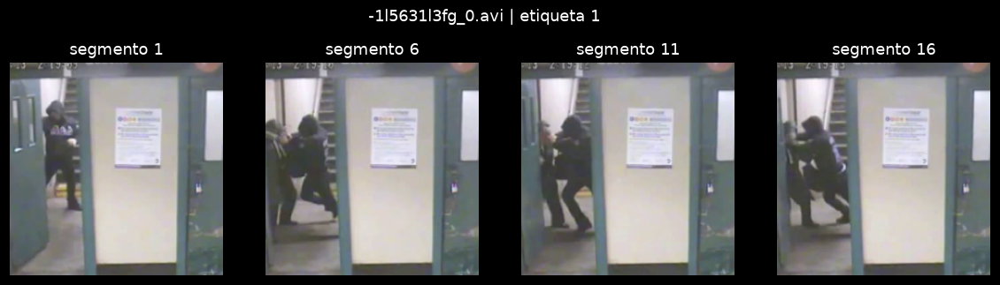

In [ ]:
import warnings
_CACHE_LOCK = threading.Lock()

# Lista global para almacenar videos corruptos o con fallas de lectura
VIDEOS_CORRUPTOS = []

def cache_path(key):
    return CACHE_DIR / f"{hashlib.sha1(key.encode()).hexdigest()[:16]}{Path(key).suffix.lower() or '.mp4'}"


def trim_cache(protected=None, min_free_gb=15, keep_recent_s=900):
    with _CACHE_LOCK:
        files = []
        for p in CACHE_DIR.iterdir():
            try:
                if p.is_file() and '.part' not in p.name:
                    st = p.stat(); files.append((st.st_mtime, st.st_size, p))
            except FileNotFoundError:
                pass
        total, now, limit = sum(s for _, s, _ in files), time.time(), CACHE_MAX_GB * 1024**3
        for mtime, size, p in sorted(files):
            if total <= limit and shutil.disk_usage(CACHE_DIR).free > min_free_gb * 1024**3:
                break
            if p == protected or now - mtime < keep_recent_s:
                continue
            p.unlink(missing_ok=True); total -= size


def get_local_video(key, _retry=True):
    path = cache_path(key)
    if not path.is_file() or path.stat().st_size == 0:
        trim_cache(path)
        tmp = path.with_suffix(path.suffix + f'.part.{os.getpid()}.{threading.get_ident()}')
        try:
            s3().download_file(S3_BUCKET, key, str(tmp)); tmp.replace(path)
        finally:
            tmp.unlink(missing_ok=True)
    try:
        os.utime(path, None)
    except FileNotFoundError:
        if not _retry: raise
        return get_local_video(key, _retry=False)
    return path


def s3_size_gb(keys):
    sizes = {}
    for prefix in sorted({k.split('/')[0] + '/' for k in keys if '/' in k}):
        for page in s3().get_paginator('list_objects_v2').paginate(Bucket=S3_BUCKET, Prefix=prefix):
            sizes.update({o['Key']: o['Size'] for o in page.get('Contents', [])})
    return sum(sizes.get(k, 0) for k in keys) / 1024**3


def prefetch(keys, threads=8):
    with ThreadPoolExecutor(threads) as ex:
        list(tqdm(ex.map(get_local_video, keys), total=len(keys), desc='Descarga a caché'))


def video_meta(path):
    cap = cv2.VideoCapture(str(path))
    n, fps = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), cap.get(cv2.CAP_PROP_FPS)
    cap.release()
    return n, (fps if fps and fps > 1 else 30.0)


def resize_short(frame, short):
    h, w = frame.shape[:2]; s = short / min(h, w)
    return cv2.resize(frame, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR)


def read_frames(path, indices, short):
    """Frames RGB con lado corto = short, en el orden de `indices`."""
    n, _ = video_meta(path)
    wanted = sorted(set(int(i) for i in indices))
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened(): raise RuntimeError(f'No se pudo abrir {path.name}')
    out = {}
    try:
        if n <= MAX_FRAMES_SECUENCIAL:
            target, i = set(wanted), 0
            while i <= wanted[-1] and cap.grab():
                if i in target:
                    ok, fr = cap.retrieve()
                    if ok: out[i] = resize_short(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB), short)
                i += 1
        else:
            for i in wanted:
                cap.set(cv2.CAP_PROP_POS_FRAMES, i); ok, fr = cap.read()
                if ok: out[i] = resize_short(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB), short)
    finally:
        cap.release()
    missing = [i for i in wanted if i not in out]
    if not out or len(missing) > 0.25 * len(wanted):
        raise RuntimeError(f'{path.name}: {len(missing)}/{len(wanted)} frames ilegibles')
    have = np.array(sorted(out))
    for i in missing:                      # conteo de frames inexacto en el contenedor
        out[i] = out[int(have[np.abs(have - i).argmin()])]
    return [out[int(i)] for i in indices]


def segment_indices(total, training, rng=None):
    """Metodología 1.2: N segmentos de largo L = floor(F/N); aleatorio en train, central en eval."""
    L = total // N_FRAMES
    if L < 1:
        return np.linspace(0, total - 1, N_FRAMES).round().astype(int).tolist()
    starts = np.arange(N_FRAMES) * L
    return (starts + (rng.integers(0, L, N_FRAMES) if training else L // 2)).tolist()


def to_tensor(frames):
    """Metodología 1.3: recorte central CROP, escala [0,1] y estandarización -> [C,T,H,W]."""
    x = torch.from_numpy(np.stack(frames)).permute(0, 3, 1, 2).float().div_(255)        # [T,C,H,W]
    h, w = x.shape[-2:]; top, left = (h - CROP) // 2, (w - CROP) // 2
    x = x[..., top:top + CROP, left:left + CROP]
    x = (x - torch.tensor(MEAN).view(1, 3, 1, 1)) / torch.tensor(STD).view(1, 3, 1, 1)
    return x.permute(1, 0, 2, 3).contiguous()


def denorm(x):
    """[C,T,H,W] normalizado -> [T,H,W,C] en [0,1] para graficar."""
    x = x * torch.tensor(STD).view(3, 1, 1, 1) + torch.tensor(MEAN).view(3, 1, 1, 1)
    return x.clamp(0, 1).permute(1, 2, 3, 0).numpy()


class VideoDataset(Dataset):
    def __init__(self, frame, training):
        self.frame, self.training = frame.reset_index(drop=True), training

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, ix):
        row = self.frame.iloc[ix]
        try:
            path = get_local_video(row.s3_key)
            total, _ = video_meta(path)
            if total < 1:
                raise RuntimeError(f"Video sin frames válidos: {row.s3_key}")
            rng = np.random.default_rng(random.getrandbits(32))
            frames = read_frames(path, segment_indices(total, self.training, rng), SHORT_SIDE)
            return to_tensor(frames), torch.tensor(float(row.y)), row.s3_key
        except Exception as e:
            # Almacenar en la lista de revisión manual
            if row.s3_key not in VIDEOS_CORRUPTOS:
                VIDEOS_CORRUPTOS.append(row.s3_key)
            warnings.warn(f"Error leyendo {row.s3_key} ({type(e).__name__}). Reintentando con otro video aleatorio.")

            # Elegir otro índice del dataset de forma recursiva
            alt_ix = random.randint(0, len(self.frame) - 1)
            return self.__getitem__(alt_ix)


def make_loader(frame, training):
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(VideoDataset(frame, training), batch_size=BATCH_SIZE, shuffle=training, num_workers=NUM_WORKERS,
                      pin_memory=AMP, worker_init_fn=seed_worker, generator=g, persistent_workers=NUM_WORKERS > 0)


if MODO == 'COMPLETO':
    keys_pub = pd.concat([df_train, df_val, df_test]).s3_key.tolist()
    try:
        total_gb = s3_size_gb(keys_pub)
    except ClientError:
        total_gb = float('inf')
    print(f'Videos públicos: {total_gb:.1f} GB | caché disponible: {CACHE_MAX_GB:.1f} GB')
    if total_gb <= 0.9 * CACHE_MAX_GB:
        prefetch(keys_pub)
    else:
        print('No caben todos en el disco: se descargan a demanda (más lento). Considerar agrandar el volumen EBS.')

train_loader, val_loader, test_loader = (make_loader(d, t) for d, t in ((df_train, True), (df_val, False), (df_test, False)))

x0, y0, k0 = val_loader.dataset[0]
assert x0.shape == (3, N_FRAMES, CROP, CROP), x0.shape
v0 = denorm(x0)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, t in zip(axes, np.linspace(0, N_FRAMES - 1, 4).astype(int)):
    ax.imshow(v0[t]); ax.set_title(f'segmento {t + 1}'); ax.axis('off')
fig.suptitle(f'{Path(k0).name} | etiqueta {int(y0)}'); plt.show()

## 6. Métricas y pruebas estadísticas
**Métrica primaria (metodología 5.1):** AUC-ROC, la probabilidad de que un video violento reciba un score mayor que uno no violento, independiente del umbral:

$$\mathrm{AUC}=\Pr\big(\hat p(v^+) > \hat p(v^-)\big).$$

**Métricas complementarias** con umbral $\tau=0.5$, siendo $\hat y=\mathbb{1}[\hat p\ge\tau]$:

$$\text{Precisión}=\frac{TP}{TP+FP},\qquad \text{Recall}=\frac{TP}{TP+FN},\qquad F_1=\frac{2\,\text{Precisión}\cdot\text{Recall}}{\text{Precisión}+\text{Recall}},\qquad \text{Accuracy}=\frac{TP+TN}{n}.$$

**Pérdida** (entropía cruzada binaria sobre el *logit* $z$, con $\hat p=\sigma(z)=1/(1+e^{-z})$):

$$\mathcal{L}_{\text{BCE}}=-\frac{1}{n}\sum_{i=1}^{n}\big[y_i\log\hat p_i+(1-y_i)\log(1-\hat p_i)\big].$$

**Incertidumbre y comparación.** IC 95 % por bootstrap estratificado por clase. La diferencia de AUC entre TSN y X3D sobre los mismos videos de test se evalúa con la prueba de DeLong et al. (1988), en la implementación rápida de Sun & Xu (2014):

$$z=\frac{\widehat{\mathrm{AUC}}_1-\widehat{\mathrm{AUC}}_2}{\sqrt{\widehat{\mathrm{Var}}_1+\widehat{\mathrm{Var}}_2-2\,\widehat{\mathrm{Cov}}_{12}}}.$$

In [ ]:
sigmoid = lambda z: 1 / (1 + np.exp(-np.asarray(z, float)))
METRICAS = ['auc', 'f1', 'precision', 'recall', 'accuracy']


def metrics(y, p, thr=THRESHOLD):
    y, p = np.asarray(y, int), np.asarray(p, float)
    yhat = (p >= thr).astype(int)
    return {'auc': roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan,
            'auprc': average_precision_score(y, p) if y.any() else np.nan,
            'f1': f1_score(y, yhat, zero_division=0), 'precision': precision_score(y, yhat, zero_division=0),
            'recall': recall_score(y, yhat, zero_division=0), 'accuracy': accuracy_score(y, yhat)}


def bce(y, z):
    return float(F.binary_cross_entropy_with_logits(torch.tensor(np.asarray(z, float)), torch.tensor(np.asarray(y, float))))


def bootstrap_table(y, p, n=N_BOOTSTRAP, seed=SEED):
    y, p = np.asarray(y, int), np.asarray(p, float)
    rng = np.random.default_rng(seed)
    strata = [np.where(y == c)[0] for c in (0, 1) if (y == c).any()]
    reps = pd.DataFrame([metrics(y[i], p[i]) for i in
                         (np.concatenate([rng.choice(s, len(s)) for s in strata]) for _ in range(n))])
    point = metrics(y, p)
    keys = ['auc', 'auprc'] + METRICAS[1:]
    return pd.DataFrame({'valor': [point[k] for k in keys], 'ic95_inf': reps[keys].quantile(0.025).values,
                         'ic95_sup': reps[keys].quantile(0.975).values}, index=keys).round(4)


def delong_test(y, p1, p2):
    y = np.asarray(y, int); pos = y == 1; m, n = pos.sum(), (~pos).sum()
    aucs, v10, v01 = [], [], []
    for p in (np.asarray(p1, float), np.asarray(p2, float)):
        tz, tx, ty = stats.rankdata(p), stats.rankdata(p[pos]), stats.rankdata(p[~pos])
        v10.append((tz[pos] - tx) / n); v01.append(1 - (tz[~pos] - ty) / m); aucs.append(v10[-1].mean())
    s = np.cov(np.vstack(v10)) / m + np.cov(np.vstack(v01)) / n
    var = s[0, 0] + s[1, 1] - 2 * s[0, 1]
    z = (aucs[0] - aucs[1]) / np.sqrt(var) if var > 0 else 0.0
    return aucs[0], aucs[1], z, 2 * stats.norm.sf(abs(z))


@torch.inference_mode()
def predict(net, loader, desc='Inferencia'):
    net.eval(); rows = []
    for x, y, keys in tqdm(loader, desc=desc, leave=False):
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            z = net(x.to(DEVICE, non_blocking=True)).reshape(-1).float()
        rows += list(zip(keys, y.int().tolist(), z.cpu().tolist()))
    out = pd.DataFrame(rows, columns=['s3_key', 'y_true', 'logit'])
    out['p'] = sigmoid(out.logit); out['y_pred'] = (out.p >= THRESHOLD).astype(int)
    return out

## 7. Baseline: Temporal Segment Networks (TSN) con ResNet-50
**Arquitectura (metodología 2.1; Wang et al., 2016).** El tensor $V\in\mathbb{R}^{B\times3\times N\times224\times224}$ se reorganiza como un lote de $B\cdot N$ imágenes. Cada frame pasa por ResNet-50, que entrega $F_k\in\mathbb{R}^{2048}$; una capa lineal produce un *logit* por frame, $z_k=W F_k+b$, y el consenso temporal promedia:

$$Z=\frac{1}{N}\sum_{k=1}^{N} z_k,\qquad P(Y=1\mid V)=\sigma(Z).$$

TSN no modela el movimiento de forma explícita: cada frame se clasifica por separado y el orden temporal no influye en el resultado.

**Carga desde S3.** El modelo ya fue entrenado (metodología 2.2) y aquí solo se evalúa. La función de carga acepta los formatos habituales (`state_dict` directo, o dentro de `model_state_dict`, `state_dict` o `model`; con prefijos `module.`, `backbone.`, etc.; cabeza `fc`, `fc.1` o `classifier`). Si la cabeza tiene dos salidas con softmax, se convierte a un *logit* único equivalente, $z=z_1-z_0$, porque $\mathrm{softmax}(z)_1=\sigma(z_1-z_0)$. Si falta cualquier tensor del backbone, la carga se detiene con error: nunca se evalúa un modelo cargado a medias.

**Control de fuga.** El TSN se entrenó con videos del mismo manifest. Si alguno de ellos quedó en la validación o el test de este notebook, el TSN los "recuerda" y sus métricas ahí salen infladas: no miden generalización.
1. Si el checkpoint guarda la lista de videos de entrenamiento, o se entrega en `TSN_TRAIN_KEYS_S3`, esos videos se excluyen y la comparación en test es **limpia**.
2. Si no hay lista, el TSN se rotula **"TSN (vio el test)"** en todas las tablas y gráficos. Sus métricas en test son una **cota superior optimista**: una ventaja del TSN no es evidencia válida, pero una ventaja de X3D-M sí lo es, porque se obtiene frente a un baseline favorecido.
3. La comparación válida en cualquier caso es el set **municipal** (sección 15), que ningún modelo vio. Para el informe final conviene activar `EVALUAR_MUNICIPAL`.

In [ ]:
class TSN(nn.Module):
    """Metodología 2.1: ResNet-50 por frame + logit por frame + consenso promedio."""
    def __init__(self):
        super().__init__()
        self.backbone = resnet50(weights=None)
        self.backbone.fc = nn.Linear(2048, 1)

    def forward(self, x):                                       # x: [B,C,T,H,W]
        b, c, t, h, w = x.shape
        z = self.backbone(x.transpose(1, 2).reshape(b * t, c, h, w)).view(b, t)
        return z.mean(1)


def load_tsn(key):
    local = MODELS_DIR / Path(key).name
    if not local.exists():
        s3().download_file(S3_BUCKET, key, str(local))
    try:
        ck = torch.load(local, map_location='cpu', weights_only=False)
    except Exception as e:
        # Si el archivo local está corrupto, intentamos descargarlo de nuevo
        print(f'Error al leer checkpoint local ({e}). Re-descargando desde S3...')
        local.unlink(missing_ok=True)
        s3().download_file(S3_BUCKET, key, str(local))
        ck = torch.load(local, map_location='cpu', weights_only=False)

    meta = {}
    if isinstance(ck, nn.Module):
        sd = ck.state_dict()
    else:
        sd = next((ck[k] for k in ('model_state_dict', 'state_dict', 'model', 'model_state', 'net') if isinstance(ck.get(k), dict)), ck)
        meta = {k: v for k, v in ck.items() if isinstance(v, (int, float, str, bool))}
        for k, v in ck.items():                     # listas de videos guardadas en el checkpoint (p. ej. train_keys)
            vals = list(v) if isinstance(v, (list, tuple, np.ndarray, pd.Series)) else []
            if vals and all(isinstance(s, str) for s in vals[:20]) and any('/' in s for s in vals[:20]):
                print(f'El checkpoint trae {len(vals)} rutas de video en "{k}".')
                if 'test' not in k.lower() and 'val' not in k.lower():
                    meta.setdefault('_train_keys', set()).update(vals)
    clean = {}
    for k, v in sd.items():
        if not torch.is_tensor(v): continue
        changed = True
        while changed:
            changed = False
            for pre in ('module.', 'model.', 'backbone.', 'base_model.', 'net.', 'resnet.', 'encoder.'):
                if k.startswith(pre): k, changed = k[len(pre):], True
        clean[k] = v
    tsn = TSN(); target = tsn.backbone.state_dict()
    mapped = {k: clean[k] for k in target if not k.startswith('fc.') and k in clean and clean[k].shape == target[k].shape}
    heads = [(k, v) for k, v in clean.items() if k not in mapped and v.dim() == 2 and v.shape[1] == 2048 and v.shape[0] in (1, 2)]
    if len(heads) != 1:
        raise RuntimeError(f'No se identificó una cabeza única (1 o 2 x 2048): {[k for k, _ in heads]}')
    hk, hw = heads[0]; hb = clean.get(hk[:-len('weight')] + 'bias', torch.zeros(hw.shape[0]))
    if hw.shape[0] == 2:
        hw, hb = (hw[1] - hw[0])[None], (hb[1] - hb[0])[None]
        print('Cabeza softmax de 2 clases convertida a logit único (z1 - z0).')
    mapped['fc.weight'], mapped['fc.bias'] = hw, hb
    missing = sorted(set(target) - set(mapped))
    if missing:
        raise RuntimeError(f'Checkpoint TSN incompleto: faltan {len(missing)} tensores, p. ej. {missing[:5]}')
    tsn.backbone.load_state_dict(mapped)
    seen = meta.pop('_train_keys', set())
    print(f'TSN cargado desde s3://{S3_BUCKET}/{key} | cabeza: {hk} | metadatos: {meta}')
    return tsn.to(DEVICE).eval(), seen


tsn, tsn_val, tsn_test = None, pd.DataFrame(), pd.DataFrame()
tsn_seen, TSN_LIMPIO, TSN_NOMBRE = set(), False, 'TSN (vio el test)'
if not TSN_S3_KEY:
    print('TSN_S3_KEY vacío: se omite el baseline. Completar la ruta en la configuración (ver lista de la sección 3).')
else:
    try:
        tsn, tsn_seen = load_tsn(TSN_S3_KEY)
        if TSN_TRAIN_KEYS_S3:
            tsn_seen |= set(pd.read_csv(io.BytesIO(s3().get_object(Bucket=S3_BUCKET, Key=TSN_TRAIN_KEYS_S3)['Body'].read())).s3_key)
        TSN_LIMPIO = bool(tsn_seen)
        TSN_NOMBRE = 'TSN (ResNet-50)' if TSN_LIMPIO else 'TSN (vio el test)'
        if TSN_LIMPIO:
            for name, d in (('validación', df_val), ('test', df_test)):
                print(f'Videos de {name} vistos por el TSN al entrenar: {int(d.s3_key.isin(tsn_seen).sum())} de {len(d)} (se excluyen del test)')
        else:
            print('AVISO: no hay lista de videos de entrenamiento del TSN. Como se entrenó con el mismo manifest, sus métricas '
                  'en validación y test son una cota superior optimista. Comparación limpia: set municipal (sección 15).')
        tsn_val, tsn_test = predict(tsn, val_loader, 'TSN val'), predict(tsn, test_loader, 'TSN test')
        tsn_val.to_csv(RUN_DIR / 'pred_val_tsn.csv', index=False); tsn_test.to_csv(RUN_DIR / 'pred_test_tsn.csv', index=False)
        display(pd.DataFrame({'validación': metrics(tsn_val.y_true, tsn_val.p),
                              'test': metrics(tsn_test.y_true, tsn_test.p)}).T.round(4).rename_axis(TSN_NOMBRE))
    except Exception as e:
        print(f'\n[!] ERROR CRÍTICO AL CARGAR EL BASELINE TSN: {e}')
        print('Se continuará la ejecución omitiendo el baseline TSN. Solo se evaluará X3D-M.')
        tsn = None
        tsn_val, tsn_test = pd.DataFrame(), pd.DataFrame()

RuntimeError: Invalid magic number; corrupt file?

## 8. Arquitectura X3D-Medium (Rama A)
**Idea (Feichtenhofer, 2020).** X3D parte de una red 2D mínima (X2D) y la expande paso a paso, un eje a la vez, eligiendo en cada paso el eje que más mejora la precisión por unidad de cómputo. Los seis ejes son:

| Factor | Eje que expande |
|---|---|
| $\gamma_\tau$ | frecuencia de muestreo temporal |
| $\gamma_t$ | duración (número de frames) |
| $\gamma_s$ | resolución espacial |
| $\gamma_w$ | ancho (canales) |
| $\gamma_b$ | ancho del *bottleneck* |
| $\gamma_d$ | profundidad (bloques por etapa) |

El resultado es una red **delgada** (pocos canales) pero con alta resolución espaciotemporal.

**Bloque residual.** Cada bloque es un *bottleneck* $1\times1^2 \rightarrow 3\times3^2$ *depthwise* (una convolución 3D por canal) $\rightarrow 1\times1^2$, con *Squeeze-and-Excitation* en bloques alternos y activación *swish* $x\cdot\sigma(x)$:

$$\mathbf{h}_{l+1}=\mathbf{h}_l+\mathcal{F}(\mathbf{h}_l),\qquad \mathcal{F}=\mathrm{Conv}^{1\times1^2}\circ\mathrm{swish}\circ\mathrm{SE}\circ\mathrm{DWConv}^{3\times3^2}\circ\mathrm{Conv}^{1\times1^2}.$$

La convolución *depthwise* 3D cuesta $C\cdot k_t k_h k_w$ multiplicaciones por posición, en lugar de $C^2 k_t k_h k_w$ de una convolución 3D completa: es la principal fuente de eficiencia.

**X3D-M**, entrada $16\times224^2$:

| Etapa (`blocks[i]`) | Bloques | Canales (bottleneck) | Salida $T\times H\times W$ |
|---|---|---|---|
| `blocks[0]` conv1 (stem) | — | 24 | $16\times112^2$ |
| `blocks[1]` res2 | 3 | 24 (54) | $16\times56^2$ |
| `blocks[2]` res3 | 5 | 48 (108) | $16\times28^2$ |
| `blocks[3]` res4 | 11 | 96 (216) | $16\times14^2$ |
| `blocks[4]` res5 | 7 | 192 (432) | $16\times7^2$ |
| `blocks[5]` cabeza | conv5 → *pool* → fc 2048 → **fc 1 (nueva)** | 432 → 2048 → 1 | $1$ |

La dimensión temporal no se reduce en ninguna etapa, lo que permite mapas de calor con resolución de frame (sección 13). El *pooling* de la cabeza original tiene un kernel fijo de $16\times7\times7$; se reemplaza por un *pooling* adaptativo global, que es idéntico para $16\times224^2$ y además admite $N=32$ (opción de la metodología 1.2).

**Adaptación binaria (metodología 3.2).** Se carga X3D-M preentrenado en Kinetics-400. La proyección de 400 clases se reemplaza por una neurona lineal (*logit* $z$, inicializada con $\mathcal{N}(0,0.01^2)$) y se elimina el Softmax de PyTorchVideo, porque `BCEWithLogitsLoss` aplica la sigmoide internamente y es numéricamente estable.

**Qué se entrena en cada fase.**
- **Fase 1:** solo la neurona nueva.
- **Fase 2:** la neurona nueva, la cabeza (conv5 y fc 2048) y las últimas `UNFREEZE_STAGES` etapas (por defecto res4 y res5).

**BatchNorm.** Las estadísticas de BatchNorm quedan congeladas. En la Fase 1 es obligatorio: una capa congelada con BatchNorm en modo entrenamiento seguiría modificando sus medias y varianzas sin que sus pesos se entrenen. En la Fase 2, con lotes de 4 videos, las estadísticas del lote son demasiado ruidosas (Wu & He, 2018).

In [ ]:
def build_x3d():
    from pytorchvideo.models.hub.x3d import x3d_m
    net = x3d_m(pretrained=True)
    head = net.blocks[-1]
    head.pool.pool = nn.AdaptiveAvgPool3d(1)          # el pooling original es fijo para 16x7x7: así admite N=16 o 32
    head.dropout, head.activation = nn.Dropout(DROPOUT), None
    head.proj = nn.Linear(head.proj.in_features, 1)
    nn.init.normal_(head.proj.weight, std=0.01); nn.init.zeros_(head.proj.bias)
    return net


def set_phase(net, phase):
    net.requires_grad_(False)
    modules = [net.blocks[-1].proj] if phase == 1 else list(net.blocks[-1 - UNFREEZE_STAGES:])
    for m in modules: m.requires_grad_(True)


def freeze_bn_stats(net):
    for m in net.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm): m.eval()


x3d = build_x3d().to(DEVICE)
X3D_TARGET_LAYER = x3d.blocks[-2]
rows = []
for i, b in enumerate(x3d.blocks):
    out = b.res_blocks if hasattr(b, 'res_blocks') else None
    rows.append({'bloque': f'blocks[{i}]', 'tipo': type(b).__name__, 'sub-bloques': len(out) if out is not None else '—',
                 'parámetros': sum(p.numel() for p in b.parameters())})
display(pd.DataFrame(rows).set_index('bloque'))
for ph in (1, 2):
    set_phase(x3d, ph)
    print(f'Fase {ph}: {sum(p.numel() for p in x3d.parameters() if p.requires_grad):,} parámetros entrenables '
          f'de {sum(p.numel() for p in x3d.parameters()):,}')

x3d.eval()
with torch.inference_mode(), torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
    z0 = x3d(x0[None].to(DEVICE)).reshape(-1)
assert z0.shape == (1,) and torch.isfinite(z0).all()
print('Forward OK | logit inicial:', round(float(z0), 4))

,tipo,sub-bloques,parámetros
bloque,,,
blocks[0],ResNetBasicStem,—,816
blocks[1],ResStage,3,15370
blocks[2],ResStage,5,73248
blocks[3],ResStage,11,569256
blocks[4],ResStage,7,1347440
blocks[5],ResNetBasicHead,—,970593


Fase 1: 2,049 parámetros entrenables de 2,976,723
Fase 2: 2,887,289 parámetros entrenables de 2,976,723
Forward OK | logit inicial: 0.1487


## 9. Entrenamiento en dos fases (metodología 3.2)
| | Fase 1: adaptación inicial | Fase 2: ajuste fino progresivo |
|---|---|---|
| Épocas | 5 | 15 |
| Parámetros entrenables | neurona de salida | res4, res5 y cabeza |
| Optimizador | AdamW, $\eta=10^{-3}$ constante | AdamW nuevo, $\eta_0=10^{-5}$ con *cosine annealing* |

*Cosine annealing* en la Fase 2, con $e$ la época dentro de la fase y $E_2=15$:

$$\eta_e=\eta_{\min}+\tfrac{1}{2}(\eta_0-\eta_{\min})\Big(1+\cos\frac{\pi e}{E_2}\Big),\qquad \eta_{\min}=10^{-7}.$$

AdamW (Loshchilov & Hutter, 2019) aplica el *weight decay* desacoplado del gradiente. Se usa precisión mixta fp16 (Tensor Cores de la T4) y acumulación de gradiente para un batch efectivo de 8 videos.

**Registro por época** (sección 10):
- Pérdida, AUC, F1, precisión, *recall* y *accuracy*, en entrenamiento y en validación.
- Tiempo de cómputo de la época (s), tiempo de validación y pico de VRAM (MB).
- Las métricas de entrenamiento se calculan sobre las predicciones hechas durante la misma época (con *dropout* activo y pesos cambiando), así que son algo pesimistas respecto de una evaluación posterior.

**Selección.** `best.pt` es la época de mayor AUC en **validación**; el test no se usa durante el entrenamiento. `last.pt` se guarda en cada época: si la instancia se interrumpe, con `REANUDAR=True` el entrenamiento continúa donde quedó.

In [ ]:
CONFIG_SIG = dict(n_frames=N_FRAMES, norm=NORMALIZACION, f1=(FASE1_EPOCHS, FASE1_LR), f2=(FASE2_EPOCHS, FASE2_LR),
                  unfreeze=UNFREEZE_STAGES, split=split_file.name)


def build_opt(phase):
    params = [p for p in x3d.parameters() if p.requires_grad]
    if phase == 1:
        return torch.optim.AdamW(params, lr=FASE1_LR, weight_decay=WEIGHT_DECAY), None
    opt = torch.optim.AdamW(params, lr=FASE2_LR, weight_decay=WEIGHT_DECAY)
    return opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FASE2_EPOCHS, eta_min=FASE2_LR * 1e-2)


def atomic_save(payload, dest):
    tmp = dest.with_suffix('.tmp'); torch.save(payload, tmp); os.replace(tmp, dest)


def train_x3d():
    # Forzamos temporalmente a los loaders a usar num_workers=0 para evitar fallas con OpenCV y multiprocesamiento
    train_loader.num_workers = 0
    val_loader.num_workers = 0
    if hasattr(train_loader, '_iterator') and train_loader._iterator is not None:
        train_loader._iterator = None
    if hasattr(val_loader, '_iterator') and val_loader._iterator is not None:
        val_loader._iterator = None

    loss_fn = nn.BCEWithLogitsLoss()
    scaler = torch.amp.GradScaler(DEVICE, enabled=AMP)
    hist, start, best, best_ep, pending, cur = [], 0, -np.inf, 0, None, None
    last_f, best_f = RUN_DIR / 'last.pt', RUN_DIR / 'best.pt'
    if REANUDAR and last_f.exists():
        st = torch.load(last_f, map_location='cpu', weights_only=False)
        if st.get('config') != CONFIG_SIG:
            print(f'Configuración vieja detectada en last.pt. Eliminando checkpoint inconsistente para iniciar limpio.')
            last_f.unlink(missing_ok=True)
            best_f.unlink(missing_ok=True)
        else:
            x3d.load_state_dict(st['model']); scaler.load_state_dict(st['scaler'])
            hist, start, best, best_ep = st['hist'], st['epoch'], st['best'], st['best_ep']
            pending = (st['phase'], st['opt'], st['sched'])
            print(f'Reanudando en la época {start + 1}; mejor época hasta ahora: {best_ep}.')

    for ep in range(start, EPOCHS):
        phase = 1 if ep < FASE1_EPOCHS else 2
        if phase != cur:
            set_phase(x3d, phase); opt, sched = build_opt(phase); cur = phase
            if pending and pending[0] == phase:
                opt.load_state_dict(pending[1])
                if sched: sched.load_state_dict(pending[2])
            pending = None
        x3d.train()
        if phase == 1 or FREEZE_BN: freeze_bn_stats(x3d)
        if AMP: torch.cuda.reset_peak_memory_stats()
        t0 = time.perf_counter(); opt.zero_grad(set_to_none=True)
        ys, zs = [], []
        for step, (x, y, _) in enumerate(tqdm(train_loader, desc=f'Época {ep + 1}/{EPOCHS} (fase {phase})', leave=False)):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
                z = x3d(x).reshape(-1).float()
            loss = loss_fn(z, y)
            scaler.scale(loss / ACCUM_STEPS).backward()
            if (step + 1) % ACCUM_STEPS == 0 or step + 1 == len(train_loader):
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            ys += y.int().tolist(); zs += z.detach().cpu().tolist()
        t_train = time.perf_counter() - t0
        lr = opt.param_groups[0]['lr']
        if sched: sched.step()
        vram = torch.cuda.max_memory_allocated() / 1024**2 if AMP else np.nan

        t0 = time.perf_counter(); pv = predict(x3d, val_loader, 'Validación'); t_val = time.perf_counter() - t0
        tm, vm = metrics(ys, sigmoid(zs)), metrics(pv.y_true, pv.p)
        row = {'epoch': ep + 1, 'fase': phase, 'lr': lr, 'train_loss': bce(ys, zs), 'val_loss': bce(pv.y_true, pv.logit),
               **{f'train_{k}': tm[k] for k in METRICAS}, **{f'val_{k}': vm[k] for k in METRICAS},
               'seg_entrenamiento': t_train, 'seg_validacion': t_val, 'vram_mb': vram}
        hist.append(row)
        score = vm['auc'] if np.isfinite(vm['auc']) else -row['val_loss']
        improved = score > best
        if improved: best, best_ep = score, ep + 1
        payload = dict(model=x3d.state_dict(), opt=opt.state_dict(), sched=sched.state_dict() if sched else None,
                       scaler=scaler.state_dict(), phase=phase, epoch=ep + 1, best=best, best_ep=best_ep, hist=hist, config=CONFIG_SIG)
        atomic_save(payload, last_f)
        if improved: atomic_save(payload, best_f)
        pd.DataFrame(hist).to_csv(RUN_DIR / 'history.csv', index=False)
        print(f"Época {ep + 1:>2} (fase {phase}) | loss {row['train_loss']:.4f}/{row['val_loss']:.4f} | "
              f"AUC val {vm['auc']:.4f} | F1 val {vm['f1']:.4f} | {t_train:.0f} s | VRAM {vram:.0f} MB" + ('  <- mejor' if improved else ''))
    return pd.DataFrame(hist)


history = train_x3d()

Época 1/20 (fase 1):   0%|          | 0/1329 [00:00<?, ?it/s]

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x27003e40] moov atom not found
/tmp/ipykernel_1877/1461072476.py:146: UserWarning: Error leyendo Raw Videos/XD-Violence/Normal/Normal_v=8cTqh9tMz_I___1_label_A.mp4 (RuntimeError). Reintentando con otro video aleatorio.
  warnings.warn(f"Error leyendo {row.s3_key} ({type(e).__name__}). Reintentando con otro video aleatorio.")
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x270e5c40] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x620e4d00] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x62954f80] Referenced QT chapter track not found
Exception ignored in: <function tqdm.__del__ at 0x7c2789ccab60>
Traceback (most recent call last):
  File "/opt/pytorch/lib/python3.13/site-packages/tqdm/std.py", line 1154, in __del__
    self.close()
  File "/opt/pytorch/lib/python3.13/site-packages/tqdm/notebook.py", line 279, in close
    self.disp(bar_style='danger', check_delay=False)
AttributeError: 'tqdm' object has no attribute 'disp'
[mov,mp4,m4a,3gp,

## 10. Indicadores por época
Para cada época se grafican, en entrenamiento y validación:
- Las métricas de la metodología 5.1: pérdida BCE, AUC-ROC, F1, precisión, *recall* y *accuracy* (con $\tau=0.5$).
- Los costos de la metodología 5.2: tiempo de cómputo por época y pico de VRAM.

Elementos de referencia en los gráficos:
- **Línea gris punteada:** paso de la Fase 1 a la Fase 2.
- **Línea amarilla:** mejor época según AUC de validación.
- **Línea violeta discontinua:** desempeño del baseline TSN en validación (optimista si el TSN vio esos videos al entrenar).

**Cómo leerlos.**
- Una brecha creciente entre entrenamiento y validación, con la pérdida de validación subiendo, indica sobreajuste.
- El salto al iniciar la Fase 2 mide el aporte de ajustar las capas convolucionales frente a solo entrenar la cabeza.
- F1, precisión y *recall* dependen del umbral fijo 0.5. Pueden oscilar aunque el AUC esté estable: el modelo puede ordenar bien los videos y aun así cambiar su escala de probabilidades.

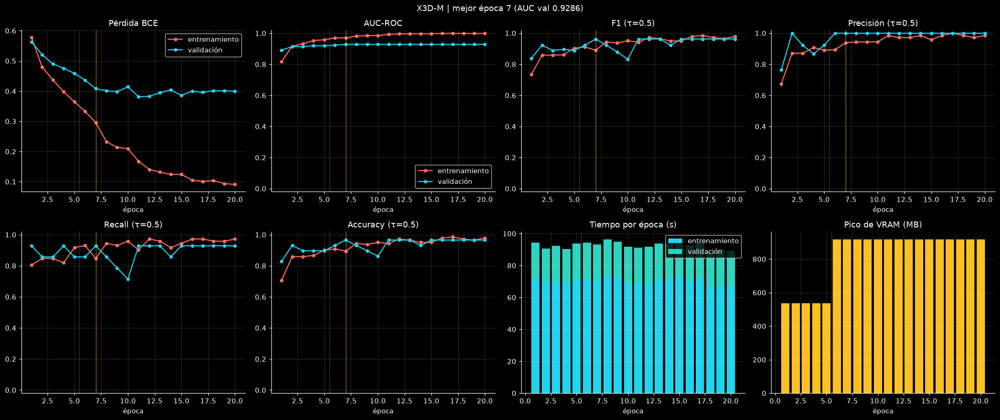

,fase,lr,train_loss,val_loss,val_auc,val_f1,val_precision,val_recall,val_accuracy,seg_entrenamiento,vram_mb
epoch,,,,,,,,,,,
1,1,0.001,0.5777,0.5632,0.8905,0.8387,0.7647,0.9286,0.8276,71.0165,536.0889
2,1,0.001,0.4796,0.5203,0.9143,0.9231,1.0000,0.8571,0.9310,68.0337,536.0889
3,1,0.001,0.4370,0.4901,0.9143,0.8889,0.9231,0.8571,0.8966,69.7937,536.0889
4,1,0.001,0.3981,0.4757,0.9190,0.8966,0.8667,0.9286,0.8966,67.7669,536.0889
5,1,0.001,0.3647,0.4587,0.9190,0.8889,0.9231,0.8571,0.8966,71.1074,536.0889
6,2,0.000,0.3331,0.4365,0.9238,0.9231,1.0000,0.8571,0.9310,71.3033,918.0200
7,2,0.000,0.2959,0.4082,0.9286,0.9630,1.0000,0.9286,0.9655,70.4969,918.0034
8,2,0.000,0.2326,0.4010,0.9286,0.9231,1.0000,0.8571,0.9310,73.1624,918.0034
9,2,0.000,0.2136,0.3984,0.9286,0.8800,1.0000,0.7857,0.8966,72.3944,918.0034


Tiempo medio por época: 69.9 s | VRAM pico: 918 MB


In [ ]:
history = pd.read_csv(RUN_DIR / 'history.csv')
best_ep = int(history.loc[history.val_auc.fillna(-1).idxmax(), 'epoch'])
tsn_ref = metrics(tsn_val.y_true, tsn_val.p) if not tsn_val.empty else None
titles = {'loss': 'Pérdida BCE', 'auc': 'AUC-ROC', 'f1': 'F1 (τ=0.5)', 'precision': 'Precisión (τ=0.5)',
          'recall': 'Recall (τ=0.5)', 'accuracy': 'Accuracy (τ=0.5)'}
fig, axes = plt.subplots(2, 4, figsize=(20, 8.5))
for ax, (k, title) in zip(axes.flat, titles.items()):
    ax.plot(history.epoch, history[f'train_{k}'], 'o-', ms=4, label='entrenamiento')
    ax.plot(history.epoch, history[f'val_{k}'], 'o-', ms=4, label='validación')
    if tsn_ref and k != 'loss':
        ax.axhline(tsn_ref[k], color=PALETA[3], ls='--', lw=1.2, label=f'{TSN_NOMBRE} en val')
    ax.set(title=title, xlabel='época')
    if k != 'loss': ax.set_ylim(-0.02, 1.02)
ax = axes.flat[6]
ax.bar(history.epoch, history.seg_entrenamiento, color=PALETA[1], label='entrenamiento')
ax.bar(history.epoch, history.seg_validacion, bottom=history.seg_entrenamiento, color=PALETA[4], label='validación')
ax.set(title='Tiempo por época (s)', xlabel='época')
ax = axes.flat[7]
ax.bar(history.epoch, history.vram_mb, color=PALETA[2]); ax.set(title='Pico de VRAM (MB)', xlabel='época')
for ax in axes.flat:
    if FASE1_EPOCHS < EPOCHS: ax.axvline(FASE1_EPOCHS + 0.5, color='gray', ls=':', lw=1)
for ax in axes.flat[:6]:
    ax.axvline(best_ep, color=PALETA[2], ls='-', lw=0.8, alpha=0.7)
axes.flat[0].legend(); axes.flat[1].legend(); axes.flat[6].legend()
fig.suptitle(f'X3D-M | mejor época {best_ep} (AUC val {history.val_auc.max():.4f})')
fig.tight_layout(); fig.savefig(RUN_DIR / 'indicadores_por_epoca.png', dpi=150); plt.show()

cols = ['epoch', 'fase', 'lr', 'train_loss', 'val_loss'] + [f'val_{k}' for k in METRICAS] + ['seg_entrenamiento', 'vram_mb']
display(history[cols].round(4).set_index('epoch'))
print(f'Tiempo medio por época: {history.seg_entrenamiento.mean():.1f} s | VRAM pico: {history.vram_mb.max():.0f} MB')

## 11. Evaluación final en test y comparación con el baseline
Se carga el mejor checkpoint de X3D-M (elegido en validación) y se evalúa **una sola vez** en el test, junto al TSN, sobre los mismos videos. Si se conoce la lista de entrenamiento del TSN, se excluyen esos videos; si no, el TSN aparece como "vio el test" y su resultado es optimista (sección 7).

La tabla reporta cada métrica con su IC 95 % por bootstrap, y la prueba de DeLong indica si la diferencia de AUC es estadísticamente significativa. Una diferencia con $p\ge0.05$ debe reportarse como **no concluyente**, no como que un modelo es mejor.

X3D val:   0%|          | 0/8 [00:00<?, ?it/s]

X3D test:   0%|          | 0/8 [00:00<?, ?it/s]

Videos de test comparables: 29 de 29


,auc,auprc,f1,precision,recall,accuracy
X3D-M,"0.881 [0.743, 0.976]","0.885 [0.767, 0.977]","0.800 [0.647, 0.929]","0.750 [0.591, 0.929]","0.857 [0.643, 1.000]","0.793 [0.621, 0.931]"


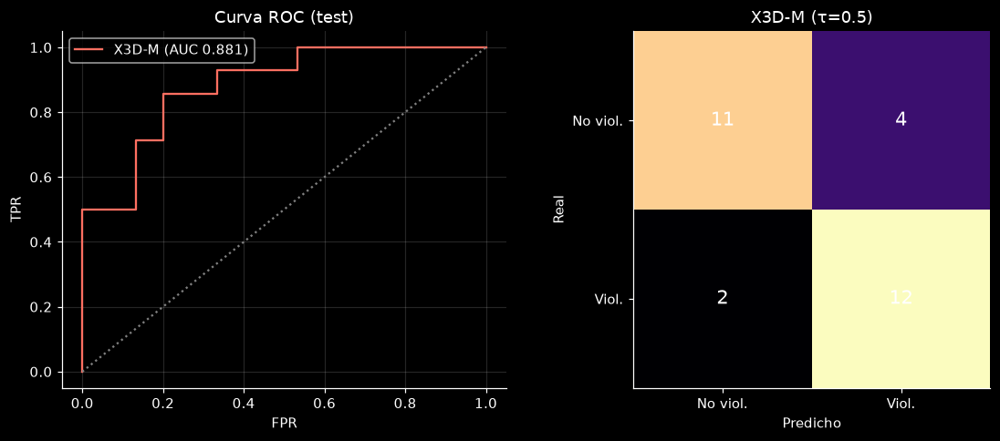

,,n,auc,f1,precision,recall,accuracy
fuente,modelo,,,,,,
RWF,X3D-M,8,1.000,1.000,1.000,1.00,1.000
UFC-Crime,X3D-M,8,0.688,0.667,0.600,0.75,0.625
XD-Violence,X3D-M,13,0.900,0.727,0.667,0.80,0.769


In [ ]:
best_state = torch.load(RUN_DIR / 'best.pt', map_location='cpu', weights_only=False)
x3d.load_state_dict(best_state['model'])
x3d_val, x3d_test = predict(x3d, val_loader, 'X3D val'), predict(x3d, test_loader, 'X3D test')
x3d_val.to_csv(RUN_DIR / 'pred_val_x3d.csv', index=False); x3d_test.to_csv(RUN_DIR / 'pred_test_x3d.csv', index=False)

comparable = sorted(set(df_test.s3_key) - tsn_seen)
models_test = {'X3D-M': x3d_test.set_index('s3_key').loc[comparable]}
if not tsn_test.empty:
    models_test[TSN_NOMBRE] = tsn_test.set_index('s3_key').loc[comparable]
y_cmp = models_test['X3D-M'].y_true.to_numpy()
print(f'Videos de test comparables: {len(comparable)} de {len(df_test)}')

tables = {name: bootstrap_table(y_cmp, d.p) for name, d in models_test.items()}
summary = pd.DataFrame({name: {m: f"{t.loc[m, 'valor']:.3f} [{t.loc[m, 'ic95_inf']:.3f}, {t.loc[m, 'ic95_sup']:.3f}]"
                               for m in t.index} for name, t in tables.items()}).T
display(summary)
if len(models_test) == 2 and len(np.unique(y_cmp)) == 2:
    a1, a2, z, p = delong_test(y_cmp, models_test['X3D-M'].p, models_test[TSN_NOMBRE].p)
    print(f'DeLong: AUC X3D-M {a1:.4f} vs TSN {a2:.4f} | z = {z:.3f} | p = {p:.4f}'
          + (' -> diferencia significativa' if p < 0.05 else ' -> diferencia no concluyente'))
    if not TSN_LIMPIO:
        print('El TSN vio estos videos al entrenar: una ventaja del TSN aquí no es evidencia válida; '
              'una ventaja de X3D-M sí lo es, porque se obtuvo frente a un baseline favorecido.')

fig, axes = plt.subplots(1, 1 + len(models_test), figsize=(6 + 4.5 * len(models_test), 4.5))
for c, (name, d) in zip(PALETA, models_test.items()):
    if len(np.unique(y_cmp)) == 2:
        fpr, tpr, _ = roc_curve(y_cmp, d.p)
        axes[0].plot(fpr, tpr, color=c, label=f'{name} (AUC {roc_auc_score(y_cmp, d.p):.3f})')
axes[0].plot([0, 1], [0, 1], ':', color='gray'); axes[0].set(title='Curva ROC (test)', xlabel='FPR', ylabel='TPR'); axes[0].legend()
for ax, (name, d) in zip(axes[1:], models_test.items()):
    cm = confusion_matrix(y_cmp, d.y_pred, labels=[0, 1])
    ax.imshow(cm, cmap='magma'); ax.grid(False)
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha='center', va='center', color='w', fontsize=14)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['No viol.', 'Viol.'], yticklabels=['No viol.', 'Viol.'],
           xlabel='Predicho', ylabel='Real', title=f'{name} (τ=0.5)')
fig.tight_layout(); fig.savefig(RUN_DIR / 'comparacion_test.png', dpi=150); plt.show()

por_fuente = []
for name, d in models_test.items():
    for f, g in d.join(df_test.set_index('s3_key')[['fuente']]).groupby('fuente'):
        por_fuente.append({'modelo': name, 'fuente': f, 'n': len(g), **metrics(g.y_true, g.p)})
display(pd.DataFrame(por_fuente).set_index(['fuente', 'modelo'])[['n'] + METRICAS].round(3))

## 12. Viabilidad de ingeniería (metodología 5.2)
Ambos modelos se miden en la misma T4, con fp16 y un video de $N$ frames por inferencia:
- **Parámetros** del modelo.
- **GFLOPs por video**, medidos con fvcore. fvcore cuenta multiplicaciones-acumulaciones, la misma convención con la que se reportan los 4.9 GFLOPs de X3D-M en la metodología.
- **Pico de VRAM en inferencia**, con un lote de `BATCH_SIZE` videos.
- **Latencia por video** (lote de 1) y ***throughput*** (videos por segundo).
- **Tiempo por época y VRAM de entrenamiento:** solo para X3D-M. El TSN se cargó ya entrenado, así que su entrenamiento no se midió aquí.

**Nota sobre la tabla de la metodología 5.2.** La tabla asigna al TSN un costo "bajo". Sin embargo, el TSN procesa los $N$ frames con ResNet-50 por separado: con $N=16$ son unas $16\times4.1\approx66$ GFLOPs por video, más de diez veces X3D-M. La medición de esta celda permite corregir esa fila con datos propios.

In [ ]:
@torch.inference_mode()
def bench(net, batch, iters):
    net.eval(); x = torch.randn(batch, 3, N_FRAMES, CROP, CROP, device=DEVICE)
    if AMP: torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    for i in range(iters + 2):
        if i == 2:
            if AMP: torch.cuda.synchronize()
            t0 = time.perf_counter()
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            net(x)
    if AMP: torch.cuda.synchronize()
    return (time.perf_counter() - t0) / iters, (torch.cuda.max_memory_allocated() / 1024**2 if AMP else np.nan)


def gflops(net):
    try:
        from fvcore.nn import FlopCountAnalysis
        fl = FlopCountAnalysis(net.eval(), torch.zeros(1, 3, N_FRAMES, CROP, CROP, device=DEVICE))
        fl.unsupported_ops_warnings(False); fl.uncalled_modules_warnings(False)
        return fl.total() / 1e9
    except Exception as exc:
        print('FLOPs no medibles:', type(exc).__name__, str(exc)[:150]); return np.nan


iters = 3 if MODO == 'PRUEBA' else 30
costos = {}
for name, net in [('X3D-M', x3d)] + ([('TSN (ResNet-50)', tsn)] if tsn is not None else []):
    lat, _ = bench(net, 1, iters); tb, vram_inf = bench(net, BATCH_SIZE, iters)
    costos[name] = {'parámetros (M)': sum(p.numel() for p in net.parameters()) / 1e6, 'GFLOPs por video': gflops(net),
                    'VRAM inferencia (MB)': vram_inf, 'latencia por video (ms)': lat * 1e3,
                    'throughput (videos/s)': BATCH_SIZE / tb}
costos['X3D-M'].update({'tiempo por época (s)': history.seg_entrenamiento.mean(), 'VRAM entrenamiento (MB)': history.vram_mb.max()})
COSTOS = pd.DataFrame(costos).T
display(COSTOS.round(2))
COSTOS.to_csv(RUN_DIR / 'costos_ingenieria.csv')

,parámetros (M),GFLOPs por video,VRAM inferencia (MB),latencia por video (ms),throughput (videos/s),tiempo por época (s),VRAM entrenamiento (MB)
X3D-M,2.98,4.9,536.06,14.23,103.67,69.94,918.02


## 13. Explicabilidad: Grad-CAM espaciotemporal
Grad-CAM (Selvaraju et al., 2017) estima qué regiones de la entrada empujaron la decisión. Se calcula a partir de las activaciones $A^k$ de la última capa convolucional y del gradiente del *logit* de violencia $Z$ respecto de ellas.

**X3D-M (3D).** Activaciones de `blocks[4]` (res5), con forma $192\times16\times7\times7$:

$$\alpha_k=\frac{1}{T'H'W'}\sum_{t,i,j}\frac{\partial Z}{\partial A^k_{t,i,j}},\qquad L_{t,i,j}=\mathrm{ReLU}\Big(\sum_k\alpha_k A^k_{t,i,j}\Big).$$

El mapa se interpola a $16\times224\times224$. Como X3D no reduce el tiempo, hay un mapa por frame muestreado, y el perfil $\bar L_t=\frac{1}{HW}\sum_{i,j}L_{t,i,j}$ indica **en qué momento** del video se concentra la evidencia.

**TSN (2D por frame).** Activaciones de `layer4` de ResNet-50 en cada frame ($2048\times7\times7$). Con consenso promedio, $\partial Z/\partial A_t=\frac{1}{N}\,\partial z_t/\partial A_t$: cada frame recibe su propio Grad-CAM, y todos se normalizan juntos para que el perfil temporal sea comparable entre frames.

**Cómo leer y límites.**
- Siempre se explica la evidencia **a favor de violencia**: en un FP muestra qué provocó la falsa alarma; en un FN, dónde el modelo encontró evidencia insuficiente.
- La resolución espacial original es $7\times7$, así que el mapa localiza regiones gruesas.
- Grad-CAM no demuestra causalidad. Su valor principal aquí es detectar **atajos**: mapas concentrados en logos, marcas de tiempo, bordes negros o fondo, en lugar de personas, indican que el modelo aprendió rasgos de la fuente y no de la acción.

Grad-CAM test:   0%|          | 0/29 [00:00<?, ?it/s]

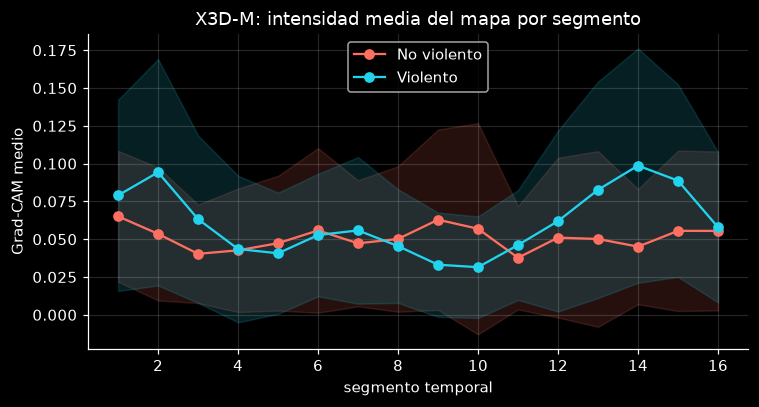

In [ ]:
def gradcam(net, layer, clip, kind):
    """Devuelve (probabilidad, mapa [T,H,W] en [0,1]) para el logit de violencia."""
    acts, grads = [], []
    def hook(_, __, out):
        acts.append(out); out.register_hook(grads.append)
    handle = layer.register_forward_hook(hook)
    req = [p.requires_grad for p in net.parameters()]
    try:
        net.eval(); net.requires_grad_(True); net.zero_grad(set_to_none=True)
        with torch.enable_grad():
            z = net(clip[None].to(DEVICE)).reshape(-1)[0]
            z.backward()
        a, g = acts[0].detach().float(), grads[0].detach().float()
        if kind == 'x3d':
            cam = F.relu((a * g.mean(dim=(2, 3, 4), keepdim=True)).sum(1, keepdim=True))
            cam = F.interpolate(cam, size=(N_FRAMES, CROP, CROP), mode='trilinear', align_corners=False)[0, 0]
        else:
            cam = F.relu((a * g.mean(dim=(2, 3), keepdim=True)).sum(1, keepdim=True))
            cam = F.interpolate(cam, size=(CROP, CROP), mode='bilinear', align_corners=False)[:, 0]
        cam = cam.cpu().numpy()
        return float(torch.sigmoid(z.detach())), (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    finally:
        handle.remove(); net.zero_grad(set_to_none=True)
        for p, r in zip(net.parameters(), req): p.requires_grad_(r)


EXPLICADORES = {'X3D-M': (x3d, X3D_TARGET_LAYER, 'x3d')}
if tsn is not None:
    EXPLICADORES['TSN'] = (tsn, tsn.backbone.layer4, 'tsn')

# Perfil temporal medio de la evidencia, por clase real, en el test
perfiles = []
for key, y in tqdm(list(zip(df_test.s3_key, df_test.y)), desc='Grad-CAM test'):
    clip, _, _ = test_loader.dataset[int(np.where(df_test.s3_key == key)[0][0])]
    for name, (net, layer, kind) in EXPLICADORES.items():
        _, cam = gradcam(net, layer, clip, kind)
        perfiles.append({'modelo': name, 'y': y, **{t: v for t, v in enumerate(cam.mean(axis=(1, 2)))}})
perfiles = pd.DataFrame(perfiles)
fig, axes = plt.subplots(1, len(EXPLICADORES), figsize=(7 * len(EXPLICADORES), 3.8), squeeze=False)
for ax, (name, g) in zip(axes[0], perfiles.groupby('modelo')):
    for c, (y, gy) in zip(PALETA, g.groupby('y')):
        m = gy[list(range(N_FRAMES))]
        ax.plot(range(1, N_FRAMES + 1), m.mean(), 'o-', color=c, label=['No violento', 'Violento'][y])
        ax.fill_between(range(1, N_FRAMES + 1), m.mean() - m.std(), m.mean() + m.std(), color=c, alpha=0.15)
    ax.set(title=f'{name}: intensidad media del mapa por segmento', xlabel='segmento temporal', ylabel='Grad-CAM medio'); ax.legend()
fig.tight_layout(); fig.savefig(RUN_DIR / 'gradcam_perfil_temporal.png', dpi=150); plt.show()

## 14. Galería: ejemplos de clasificación correcta e incorrecta
Para cada tipo de resultado de X3D-M en test se eligen los ejemplos más seguros:
- **TP:** violento clasificado como violento.
- **TN:** no violento clasificado como no violento.
- **FP:** falsa alarma.
- **FN:** violencia no detectada.

Cada ejemplo muestra:
1. **Video original**, en un GIF animado con `FRAMES_ANIMACION` frames repartidos en toda su duración, junto al mapa de calor del segmento muestreado más cercano en el tiempo.
2. **Muestra**: los frames que efectivamente vio el modelo (8 de los $N$ segmentos, ya recortados a 224×224).
3. **Mapa de calor** Grad-CAM de cada modelo sobre esos frames.
4. **Perfil temporal** de la evidencia, ubicado en segundos sobre la duración real del video.
5. **Predicción**: etiqueta real, probabilidad de cada modelo y su decisión con $\tau=0.5$.

Los GIF se guardan en `RUN_DIR/galeria/` para usarlos en las presentaciones.

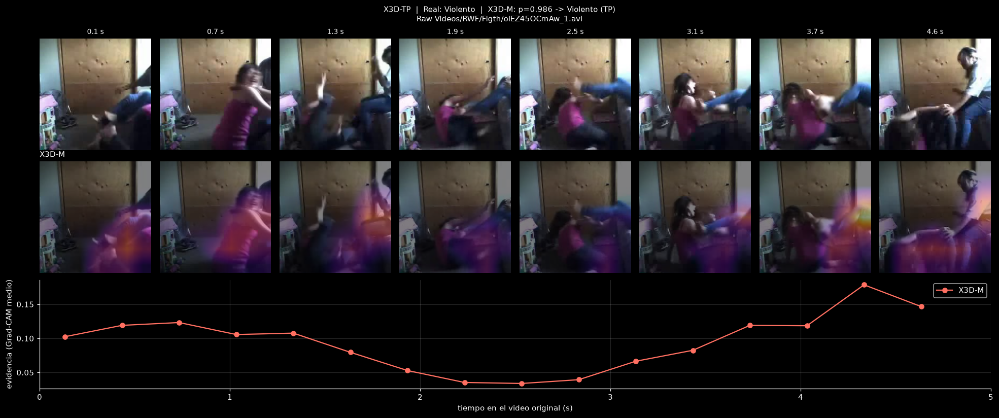

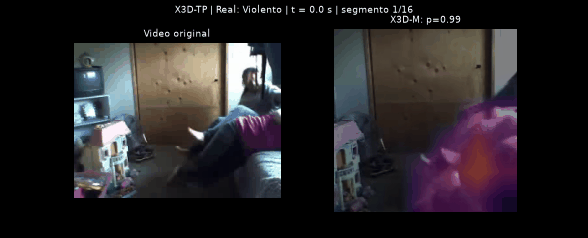

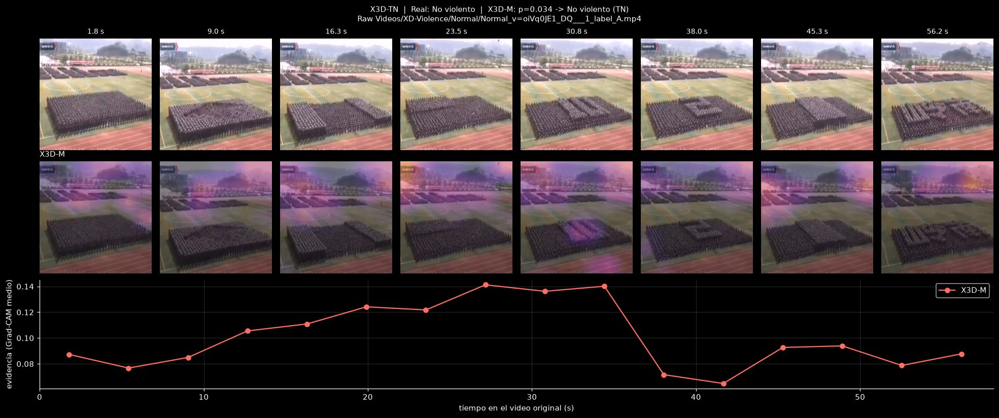

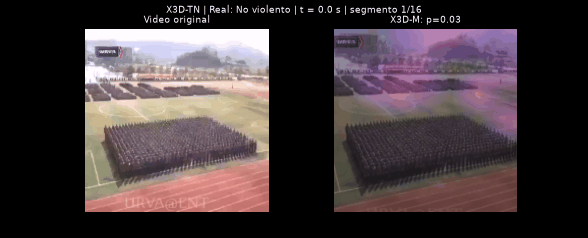

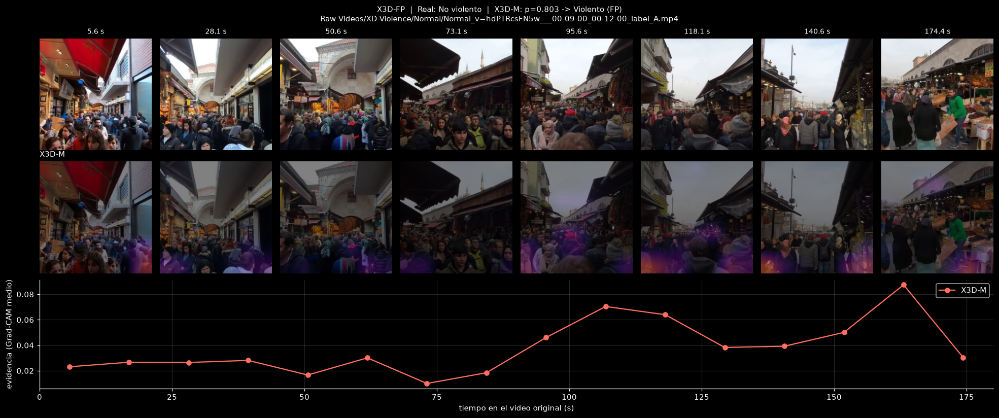

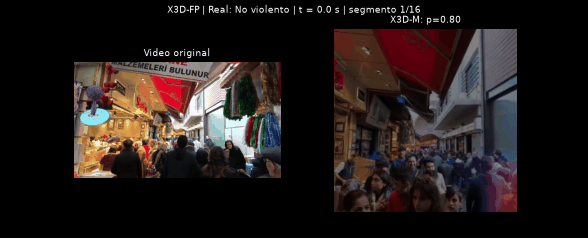

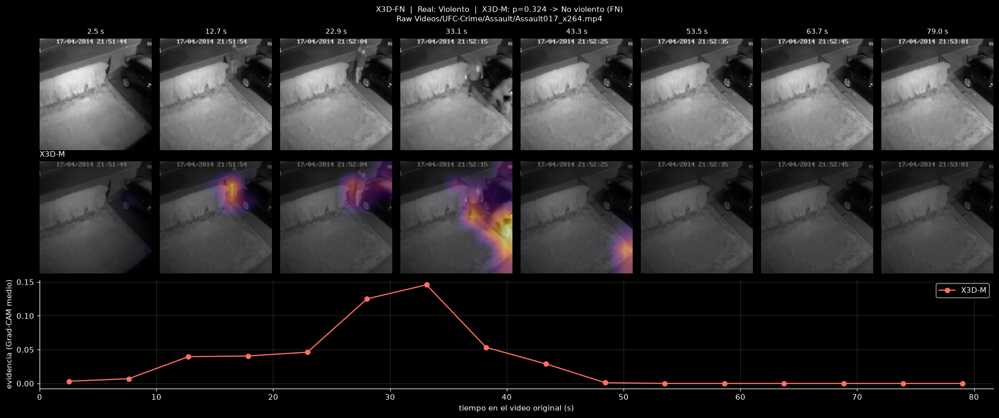

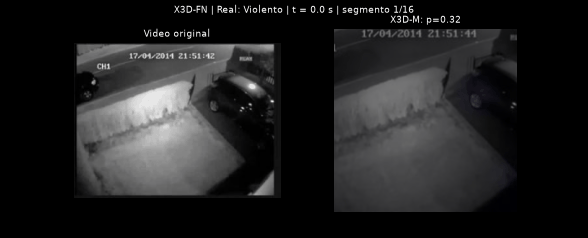

In [ ]:
GALERIA = RUN_DIR / 'galeria'; GALERIA.mkdir(exist_ok=True)
NOMBRE = {0: 'No violento', 1: 'Violento'}


def tipo_resultado(y, yhat):
    return {(1, 1): 'TP', (0, 0): 'TN', (0, 1): 'FP', (1, 0): 'FN'}[(int(y), int(yhat))]


def show_example(key, y_true, etiqueta):
    path = get_local_video(key); total, fps = video_meta(path)
    idx = segment_indices(total, False)
    clip = to_tensor(read_frames(path, idx, SHORT_SIDE)); vis = denorm(clip)
    res = {name: gradcam(net, layer, clip, kind) for name, (net, layer, kind) in EXPLICADORES.items()}
    pred_txt = '  |  '.join(f'{n}: p={p:.3f} -> {NOMBRE[int(p >= THRESHOLD)]} ({tipo_resultado(y_true, p >= THRESHOLD)})'
                            for n, (p, _) in res.items())
    title = f'{etiqueta}  |  Real: {NOMBRE[y_true]}  |  {pred_txt}\n{key}'

    # Figura estática: muestra, mapas de calor y perfil temporal
    ts = np.linspace(0, N_FRAMES - 1, 8).astype(int)
    fig = plt.figure(figsize=(18, 2.6 * (len(res) + 1) + 2.4))
    gs = fig.add_gridspec(len(res) + 2, 8, height_ratios=[1] * (len(res) + 1) + [0.9])
    for j, t in enumerate(ts):
        ax = fig.add_subplot(gs[0, j]); ax.imshow(vis[t]); ax.axis('off'); ax.set_title(f'{idx[t] / fps:.1f} s', fontsize=9)
        for r, (name, (_, cam)) in enumerate(res.items(), start=1):
            ax = fig.add_subplot(gs[r, j]); ax.imshow(vis[t]); ax.imshow(cam[t], cmap='inferno', alpha=0.5, vmin=0, vmax=1)
            ax.axis('off')
            if j == 0: ax.set_title(name, fontsize=10, loc='left')
    ax = fig.add_subplot(gs[-1, :])
    for c, (name, (_, cam)) in zip(PALETA, res.items()):
        ax.plot(np.array(idx) / fps, cam.mean(axis=(1, 2)), 'o-', color=c, label=name)
    ax.set(xlim=(0, total / fps), xlabel='tiempo en el video original (s)', ylabel='evidencia (Grad-CAM medio)'); ax.legend()
    fig.suptitle(title, fontsize=10); fig.tight_layout()
    fig.savefig(GALERIA / f'{etiqueta}_{Path(key).stem}.png', dpi=110); plt.show()

    # GIF: video original + mapa de calor del segmento más cercano
    orig_idx = np.linspace(0, total - 1, min(FRAMES_ANIMACION, total)).round().astype(int)
    orig = read_frames(path, orig_idx, 180)
    nearest = [int(np.abs(np.array(idx) - i).argmin()) for i in orig_idx]
    fig, axes = plt.subplots(1, 1 + len(res), figsize=(4.2 * (1 + len(res)), 3.4))
    ims = [axes[0].imshow(orig[0])] + [ax.imshow(vis[nearest[0]]) for ax in axes[1:]]
    ovs = [ax.imshow(res[n][1][nearest[0]], cmap='inferno', alpha=0.5, vmin=0, vmax=1) for ax, n in zip(axes[1:], res)]
    for ax in axes: ax.axis('off')
    axes[0].set_title('Video original', fontsize=9)
    for ax, n in zip(axes[1:], res): ax.set_title(f'{n}: p={res[n][0]:.2f}', fontsize=9)
    txt = fig.suptitle('', fontsize=9)

    def update(f):
        ims[0].set_data(orig[f])
        for im, ov, n in zip(ims[1:], ovs, res):
            im.set_data(vis[nearest[f]]); ov.set_data(res[n][1][nearest[f]])
        txt.set_text(f'{etiqueta} | Real: {NOMBRE[y_true]} | t = {orig_idx[f] / fps:.1f} s | segmento {nearest[f] + 1}/{N_FRAMES}')
        return ims + ovs + [txt]

    gif = GALERIA / f'{etiqueta}_{Path(key).stem}.gif'
    animation.FuncAnimation(fig, update, frames=len(orig), interval=150).save(gif, writer=animation.PillowWriter(fps=6), dpi=70)
    plt.close(fig)
    display(Image(filename=str(gif)))


gal = x3d_test.copy()
gal['tipo'] = [tipo_resultado(y, yh) for y, yh in zip(gal.y_true, gal.y_pred)]
gal['confianza'] = np.where(gal.y_pred == 1, gal.p, 1 - gal.p)
for tipo in ['TP', 'TN', 'FP', 'FN']:
    sub = gal[gal.tipo == tipo].nlargest(N_EJEMPLOS_POR_TIPO, 'confianza')
    if sub.empty:
        print(f'Sin ejemplos {tipo} en test.'); continue
    for _, r in sub.iterrows():
        show_example(r.s3_key, int(r.y_true), f'X3D-{tipo}')